In [1]:
import sys
sys.path.insert(0,'/home/favio/software/microlensing/')
from microlensing.IPM.ipm import IPM

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

In [2]:
Nbins = 400

kappa_masterlist = np.loadtxt('microlensing_mpd/kappa_list.txt')
gamma_masterlist = np.loadtxt('microlensing_mpd/gamma_list.txt')
s_masterlist     = np.loadtxt('microlensing_mpd/s_list.txt')
log10_mu         = np.loadtxt('microlensing_mpd/log10_mu.txt')

#data = np.load('/mnt/d/data/imf_with_doubles/test/mpd_grid.npy')
data = np.load('/home/favio/software/notebooks/imf_with_doubles/microlensing_mpd/data/mpd_grid_inpaint.npy')

In [3]:
min_val = 0.02
max_val = 200

logmin = np.log10(min_val)
logmax = np.log10(max_val)
logdbin = (logmax - logmin) / Nbins

bins = np.zeros(Nbins+1)
for i in range(Nbins+1):
    bins[i] = 10 ** (logmin + i * logdbin)

In [14]:
kappa = 0.52
gamma = 0.32
s     = 0.8
macro_mag = 1 / ( (1 - kappa)**2 - gamma**2 )

In [9]:
ipm = IPM(verbose=1, kappa_tot=kappa, shear=gamma, smooth_fraction=s, 
          rectangular=False, half_length_y1=12.5, half_length_y2=12.5,
          mass_function='equal',
          num_pixels_y1=10000, num_pixels_y2=10000,
          write_maps=False, write_parities=False, write_histograms=False)

ipm.random_seed = 0 # setting to 0 will cause object to generate a random seed of its own
ipm.run();

Generating star field...
Done generating star field. Elapsed time: 0.008 seconds.

Creating children and sorting stars...
Done creating children and sorting stars. Elapsed time: 0.076 seconds.

Calculating multipole and local coefficients...
Done calculating multipole and local coefficients. Elapsed time: 0.009 seconds.

Shooting cells...
100 %
Done shooting cells. Elapsed time: 338.255 seconds.



In [10]:
p_mu_luke, _ = np.histogram(ipm.magnifications.ravel()/macro_mag, bins=bins)
p_mu_luke = p_mu_luke / np.sum(p_mu_luke)

In [15]:
kappa_new = kappa
gamma_new = gamma
s_new     = s*100

log10_mu_new_index = np.arange(Nbins)

kappa_new_index = (kappa_new - kappa_masterlist[0]) / 0.01 * np.ones_like(log10_mu_new_index)
gamma_new_index = (gamma_new - gamma_masterlist[0]) / 0.01 * np.ones_like(log10_mu_new_index)
s_new_index     = (s_new - s_masterlist[0])                * np.ones_like(log10_mu_new_index)

print(kappa_new_index[0], gamma_new_index[0], s_new_index[0])

coords = np.asarray([log10_mu_new_index, kappa_new_index, gamma_new_index, s_new_index])

p_mu_interp = map_coordinates(data, coords, order=1)

47.0 32.0 80.0


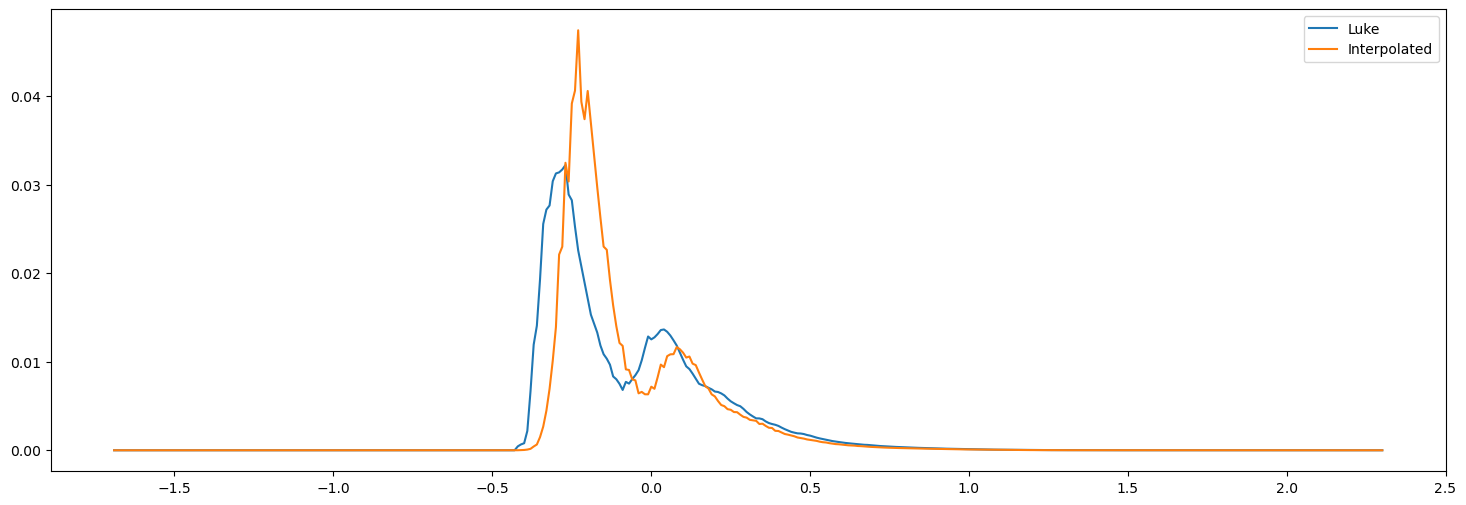

In [17]:
fig, ax = plt.subplots(1, 1, figsize=(18, 6))

ax.plot(log10_mu, p_mu_luke, label='Luke')
ax.plot(log10_mu, p_mu_interp, label='Interpolated')
ax.legend()